# Parsing

In [ ]:
pip install scapy

In [ ]:
import os

#list EVERY dataset folder path needed to pull capture files from
#if everything is in 1 dataset, just list that 1 path

#COPY YOUR PATH INTO THE LIST AS SHOWN IN EXAMPLE
dataset_paths = [
#    "/datasets/pcaps-data/VPN-PCAPS-01",
#    "/datasets/pcaps-data/VPN-PCAPs-02",

]


capture_files = []

for dataset_path in dataset_paths:
    for root, dirs, files in os.walk(dataset_path):
        for f in files:
            if f.endswith(".pcap") or f.endswith(".pcapng"):
                capture_files.append(os.path.join(root, f))

print(f"\ntotal capture files found: {len(capture_files)}")

In [ ]:
#check for duplicate files
from collections import Counter

filenames_only = [os.path.basename(f) for f in capture_files]
name_counts = Counter(filenames_only)

duplicates = {name: count for name, count in name_counts.items() if count > 1}
print(f"duplicate filenames found: {len(duplicates)}")
if duplicates:
    print(duplicates)

In [ ]:
#functions to get the label and stream id from a filename
#and the PCAP parsing function
import re
from scapy.all import PcapReader, IP, TCP, UDP

def get_stream_id(filename):
    name = filename.replace(".pcapng", "").replace(".pcap", "") #pcapng first if not it wont be replaced correctly
    match = re.match(r"^(.*)([a-zA-Z])$", name)
    if match and re.search(r"\d[a-zA-Z]$", name):
        stream_id = match.group(1)
        part = match.group(2)
    else:
        stream_id = name
        part = None
    return stream_id, part

#reads filename and assigns network and category
def get_label(filename, network_type):
    name = filename.lower()

    #activity type
    #video here means LIVE video
    #streaming means the regular non live video
    categories = {
        "chat": ["chat"],
        "email": ["email", "gmail", "mail", "thunderbird", "imap", "pop"],
        "audio": ["audio", "voip", "voipbuster", "voice"],
        "video": ["video"], 
        "file_transfer": ["ftp", "ftps", "sftp", "scp", "skype_file", "skypefile", "filetransfer", "skype_transfer"],
        "p2p": ["torrent", "bittorrent", "p2p"],
        "streaming": ["spotify", "youtube", "netflix", "vimeo"],
        "browsing": ["browsing", "facebook", "google", "twitter", "ssl"]
    }

    category = "unknown"
    for cat, keywords in categories.items():
        if any(k in name for k in keywords):
            category = cat
            break

    return network_type, category
    
#PCAP parsing function
def parse_pcap_to_flows(filepath):
    flows = {}
    with PcapReader(filepath) as pcap_reader:
        for pkt in pcap_reader:
            if IP not in pkt:
                continue
            if TCP in pkt:
                proto = "TCP"
                sport = pkt[TCP].sport
                dport = pkt[TCP].dport
            elif UDP in pkt:
                proto = "UDP"
                sport = pkt[UDP].sport
                dport = pkt[UDP].dport
            else:
                continue

            src_ip = pkt[IP].src
            dst_ip = pkt[IP].dst

            if (src_ip, sport) < (dst_ip, dport):
                flow_key = (src_ip, sport, dst_ip, dport, proto)
                direction = 1
            else:
                flow_key = (dst_ip, dport, src_ip, sport, proto)
                direction = -1

            pkt_size = len(pkt)
            pkt_time = float(pkt.time)

            if flow_key not in flows:
                flows[flow_key] = []
            flows[flow_key].append((pkt_time, pkt_size, direction))

    return flows

In [ ]:
import os
import gc
import pickle

os.makedirs("parsed_flows", exist_ok=True)

#CHECK B4 RUNNING
NETWORK_TYPE = "" 

processed_count = 0
skipped_count = 0
failed_count = 0

for filepath in capture_files:
    filename = os.path.basename(filepath)
    safe_name = filename.replace(".", "_")
    out_path = f"parsed_flows/{safe_name}.pkl"

    if os.path.exists(out_path):
        skipped_count += 1
        continue

    stream_id, part = get_stream_id(filename)
    network_type, category = get_label(filename, network_type=NETWORK_TYPE)

    try:
        file_flows = parse_pcap_to_flows(filepath)
    except Exception as e:
        print(f"failed on {filename}: {e}")
        failed_count += 1
        continue

    file_records = []
    for flow_key, packet_seq in file_flows.items():
        file_records.append({
            "filepath": filepath,
            "filename": filename,
            "stream_id": stream_id,
            "part": part,
            "network_type": network_type,
            "category": category,
            "flow_key": flow_key,
            "packet_seq": packet_seq
        })

    with open(out_path, "wb") as f:
        pickle.dump(file_records, f)

    print(f"done: {filename} -> {len(file_records)} flows")
    processed_count += 1

    del file_flows, file_records
    gc.collect()

print(f"\nbatch complete: {NETWORK_TYPE}")
print(f"newly processed: {processed_count}")
print(f"skipped (already done): {skipped_count}")
print(f"failed: {failed_count}")
print(f"total files in capture_files: {len(capture_files)}")

In [ ]:
#see which files labelled as unknown
unknown_files = df[df["category"] == "unknown"]["filename"].unique()
print(unknown_files)

In [ ]:
import glob
import pandas as pd

#only combine the pickles belonging to files from THIS batch's capture_files
#matches by filename, so it only picks up what was just parsed in this run
batch_filenames = set(os.path.basename(f) for f in capture_files)

batch_records = []
for pkl_path in glob.glob("parsed_flows/*.pkl"):
    with open(pkl_path, "rb") as f:
        file_records = pickle.load(f)
        if file_records and file_records[0]["filename"] in batch_filenames:
            batch_records.extend(file_records)

df = pd.DataFrame(batch_records)
print(f"total flows in this batch ({NETWORK_TYPE}): {len(df)}")
print(df["category"].value_counts())

#save this batch's dataframe with a name based on its network type
df.to_pickle(f"nonvpn2_files_AL2.pkl")

In [ ]:
first_row = df.iloc[0]
for col in df.columns:
    if col == "packet_seq":
        print(f"{col}: {first_row[col][:5]} ... ({len(first_row[col])} total packets)")
    else:
        print(f"{col}: {first_row[col]}")

# Loading parsed files in

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.max_columns", None) #show all columns

#load every saved batch back in
#load YOUR own .pkl files as shown in the example
non_vpn1 = pd.read_pickle("/data/nonvpn1_files_AL2.pkl")
non_vpn2 = pd.read_pickle("/data/nonvpn2_files_AL2.pkl")
non_vpn3 = pd.read_pickle("/data/nonvpn3_files_AL2.pkl")
vpn = pd.read_pickle("/data/vpn_files_AL2.pkl")
tor = pd.read_pickle("/data/tor_files_AL2.pkl")

#combine into one dataframe
df_combined = pd.concat([non_vpn1, non_vpn2, non_vpn3, vpn, tor], ignore_index=True)

print(f"total combined flows: {len(df_combined)}")

#save the final combined dataset
#you can save it in 1 file if you wish
#df_combined.to_pickle("combined_flows.pkl")

print(f"shape: {df_combined.shape}")

#percentage distribution of network_type
print(df_combined["network_type"].value_counts(normalize=True) * 100)
print()

#percentage distribution of category
print(df_combined["category"].value_counts(normalize=True) * 100)

df_combined.head(3)

total combined flows: 188670
shape: (188670, 8)
network_type
non_vpn    89.884454
vpn         9.418031
tor         0.697514
Name: proportion, dtype: float64

category
audio            65.933641
file_transfer    21.262522
chat              6.302009
email             2.912493
streaming         1.423650
video             1.327715
p2p               0.817300
browsing          0.020671
Name: proportion, dtype: float64


,filepath,filename,stream_id,part,network_type,category,flow_key,packet_seq
0,/kaggle/input/datasets/trayne/pcaps-data/NonVP...,email1a.pcap,email1,a,non_vpn,email,"(131.202.240.93, 57806, 255.255.255.255, 10505...","[(1432572763.37583, 127, 1)]"
1,/kaggle/input/datasets/trayne/pcaps-data/NonVP...,email1a.pcap,email1,a,non_vpn,email,"(131.202.240.183, 63970, 255.255.255.255, 1900...","[(1432572763.491782, 215, 1), (1432572763.4919..."
2,/kaggle/input/datasets/trayne/pcaps-data/NonVP...,email1a.pcap,email1,a,non_vpn,email,"(131.202.240.117, 54995, 255.255.255.255, 1050...","[(1432572763.515294, 131, 1)]"


In [ ]:
first_row = df_combined.iloc[0]
for col in df_combined.columns:
    if col == "packet_seq":
        print(f"{col}: {first_row[col][:5]} ... ({len(first_row[col])} total packets)")
    else:
        print(f"{col}: {first_row[col]}")

# Cleaning

In [2]:
def get_flow_duration(packet_seq):
    if len(packet_seq) < 2: #need min 2 packets to find difference
        return 0 
    timestamps = [p[0] for p in packet_seq]
    return max(timestamps) - min(timestamps)

#duration of flow
df_combined["flow_duration"] = df_combined["packet_seq"].apply(get_flow_duration)

print("description")
print(df_combined["flow_duration"].describe())
print()
print("quantile")
print(df_combined["flow_duration"].quantile([0.5, 0.75, 0.9, 0.95, 0.99, 1.0]))
print()
print("bins")
print(df_combined["flow_duration"].value_counts(bins=20).sort_index())

description
count    188670.000000
mean        252.848853
std         798.185257
min           0.000000
25%           0.144604
50%           0.412059
75%           0.421085
max        6413.501714
Name: flow_duration, dtype: float64

quantile
0.50       0.412059
0.75       0.421085
0.90     746.812158
0.95    2126.450915
0.99    4076.028234
1.00    6413.501714
Name: flow_duration, dtype: float64

bins
(-6.415, 320.675]       165223
(320.675, 641.35]         3538
(641.35, 962.025]         2894
(962.025, 1282.7]         2286
(1282.7, 1603.375]        2189
(1603.375, 1924.051]      2014
(1924.051, 2244.726]      1701
(2244.726, 2565.401]      1666
(2565.401, 2886.076]      1397
(2886.076, 3206.751]      1228
(3206.751, 3527.426]      1117
(3527.426, 3848.101]       956
(3848.101, 4168.776]       751
(4168.776, 4489.451]       570
(4489.451, 4810.126]       435
(4810.126, 5130.801]       350
(5130.801, 5451.476]       194
(5451.476, 5772.152]        79
(5772.152, 6092.827]        78
(6092.8

In [3]:
#number of packets in each flow
df_combined["packet_count"] = df_combined["packet_seq"].apply(len)

print("description")
print(df_combined["packet_count"].describe())
print()
print("quantile")
print(df_combined["packet_count"].quantile([0.5, 0.75, 0.9, 0.95, 0.99, 1.0]))
print()
print("bins")
print(df_combined["packet_count"].value_counts(bins=20).sort_index())

description
count    1.886700e+05
mean     2.182734e+02
std      1.346167e+04
min      1.000000e+00
25%      2.000000e+00
50%      2.000000e+00
75%      2.000000e+00
max      2.951457e+06
Name: packet_count, dtype: float64

quantile
0.50          2.0
0.75          2.0
0.90          4.0
0.95          6.0
0.99         71.0
1.00    2951457.0
Name: packet_count, dtype: float64

bins
(-2950.4570000000003, 147573.8]    188615
(147573.8, 295146.6]                   18
(295146.6, 442719.4]                   15
(442719.4, 590292.2]                    8
(590292.2, 737865.0]                    3
(737865.0, 885437.8]                    2
(885437.8, 1033010.6]                   2
(1033010.6, 1180583.4]                  0
(1180583.4, 1328156.2]                  0
(1328156.2, 1475729.0]                  5
(1475729.0, 1623301.8]                  0
(1623301.8, 1770874.6]                  0
(1770874.6, 1918447.4]                  0
(1918447.4, 2066020.2]                  0
(2066020.2, 2213593.0]        

In [4]:
#from above, most packets fall into first bin.
#find the number of flows that contain each packet, up to 20
print(df_combined["packet_count"].value_counts().sort_index().head(20))

packet_count
1      20923
2     133819
3        650
4      19807
5        234
6       4165
7        454
8        852
9        249
10       569
11       249
12       299
13       297
14       214
15       287
16       163
17       189
18       181
19       202
20       171
Name: count, dtype: int64


In [5]:
#distribution of network_type across each category
display(pd.crosstab(df_combined["category"], df_combined["network_type"]))

#same but as percentages within each category (row-wise)
(pd.crosstab(df_combined["category"], df_combined["network_type"], normalize="index") * 100).round(2)

network_type,non_vpn,tor,vpn
category,,,
audio,113085,26,11286
browsing,0,39,0
chat,7845,16,4029
email,5191,6,298
file_transfer,39090,6,1020
p2p,0,1065,477
streaming,1876,151,659
video,2498,7,0


network_type,non_vpn,tor,vpn
category,,,
audio,90.91,0.02,9.07
browsing,0.00,100.00,0.00
chat,65.98,0.13,33.89
email,94.47,0.11,5.42
file_transfer,97.44,0.01,2.54
p2p,0.00,69.07,30.93
streaming,69.84,5.62,24.53
video,99.72,0.28,0.00


In [6]:
#see how the duration is like for packet_count >=5
df_packet_filtered = df_combined[df_combined["packet_count"] >= 5]
print(df_packet_filtered["flow_duration"].describe())
print()
print(df_packet_filtered["flow_duration"].quantile([0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 1]))

count    13471.000000
mean      1111.686472
std       1526.169041
min          0.000846
25%          8.394011
50%        220.760416
75%       2037.051153
max       6413.501714
Name: flow_duration, dtype: float64

0.05       0.159927
0.10       0.485169
0.25       8.394011
0.50     220.760416
0.75    2037.051153
0.90    3634.037921
1.00    6413.501714
Name: flow_duration, dtype: float64


In [7]:
#the packet_count filter removed a lot of the flows with very low duration
#so dont need to filter noise from duration
MIN_PACKETS = 5 #spike at packet 2 and 4. so set min=5 to remove those noise
MIN_DURATION = 1.0 #set this to 1. duration < 1 has no meaningful temporal data

df_clean = df_combined[(df_combined["packet_count"] >= MIN_PACKETS) & (df_combined["flow_duration"] >= MIN_DURATION)].copy()
print(f"before: {len(df_combined)}, after: {len(df_clean)}")
print()
print(df_clean["flow_duration"].describe())
print()
print(df_clean["flow_duration"].quantile([0.5, 0.75, 0.90, 0.95, 0.99, 1.0]))

before: 188670, after: 11885

count    11885.000000
mean      1260.000541
std       1566.265065
min          1.000637
25%         33.422062
50%        381.199485
75%       2343.469820
max       6413.501714
Name: flow_duration, dtype: float64

0.50     381.199485
0.75    2343.469820
0.90    3814.513671
0.95    4471.033657
0.99    5521.663819
1.00    6413.501714
Name: flow_duration, dtype: float64


In [8]:
#>90% data gone, keep everything instead
df_clean = df_combined.copy()
print(df_clean.shape)

(188670, 10)


In [9]:
#percentage distribution of network_type
print(df_clean["network_type"].value_counts(normalize=True) * 100)
print()

#percentage distribution of category
print(df_clean["category"].value_counts(normalize=True) * 100)

network_type
non_vpn    89.884454
vpn         9.418031
tor         0.697514
Name: proportion, dtype: float64

category
audio            65.933641
file_transfer    21.262522
chat              6.302009
email             2.912493
streaming         1.423650
video             1.327715
p2p               0.817300
browsing          0.020671
Name: proportion, dtype: float64


In [10]:
#duration by category and network
print("=== duration by category ===")
display(df_clean.groupby("category")["flow_duration"].describe())

print("\n=== duration by network_type ===")
display(df_clean.groupby("network_type")["flow_duration"].describe())

#results:
#CATEGORY
#audio dominates count, as expected
#all except browsing are on the shorter side
#all categories have much larger avg than median: few extreme outliers to pull them up

#NETWORK
#non_vpn longest, followed by tor and vpn

=== duration by category ===


,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
audio,124397.0,308.148002,902.010096,0.0,0.409034,0.412186,0.421009,6375.836560
browsing,39.0,856.975555,1279.147892,0.0,7.251899,270.381983,1055.243825,4902.175732
chat,11890.0,29.908396,139.406081,0.0,0.123447,0.132815,0.413073,1336.179729
email,5495.0,51.562513,347.505249,0.0,0.061097,0.411198,0.420667,5619.325462
file_transfer,40116.0,206.439670,632.100413,0.0,0.410587,0.413432,0.421846,5002.507509
p2p,1542.0,28.335634,282.823962,0.0,0.097483,0.324682,4.332572,6413.501714
streaming,2686.0,93.311724,290.712883,0.0,0.039827,10.634249,95.144367,6375.836560
video,2505.0,49.530756,210.050862,0.0,0.000372,0.000435,0.263753,3703.812379



=== duration by network_type ===


,count,mean,std,min,25%,50%,75%,max
network_type,,,,,,,,
non_vpn,169585.0,273.840255,828.744838,0.0,0.410272,0.412717,0.421256,5886.010418
tor,1316.0,130.854370,601.035816,0.0,0.000310,0.302471,7.207407,6413.501714
vpn,17769.0,61.544778,375.701018,0.0,0.000717,0.001935,0.133571,4116.135039


In [11]:
#bytes by category
def get_total_bytes(packet_seq):
    return sum(p[1] for p in packet_seq)

df_clean["total_bytes"] = df_clean["packet_seq"].apply(get_total_bytes)

display(df_clean.groupby("category")["total_bytes"].describe())

#results
#all have large skews, probably from the outliers

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
audio,124397.0,1.528053e+04,1.030392e+06,46.0,128.00,128.0,256.00,1.313403e+08
browsing,39.0,1.390910e+07,3.265400e+07,60.0,1069.00,13756.0,9857955.00,1.328807e+08
chat,11890.0,5.798393e+03,9.870564e+04,60.0,128.00,131.0,306.00,3.922199e+06
email,5495.0,6.223363e+04,2.267476e+06,60.0,128.00,128.0,131.00,1.096181e+08
file_transfer,40116.0,5.459081e+05,2.383998e+07,46.0,128.00,128.0,132.00,2.430622e+09
p2p,1542.0,3.507234e+06,6.289294e+07,54.0,217.75,507.0,1985.00,1.296150e+09
streaming,2686.0,1.332289e+06,1.879215e+07,54.0,334.00,516.0,3668.25,7.850586e+08
video,2505.0,2.249168e+06,3.524088e+07,54.0,302.00,334.0,581.00,1.191458e+09


In [12]:
#sanity check: 1 stream_id : 1 category
#return empty list if everything is correct

inconsistent = df_clean.groupby("stream_id")["category"].nunique()
print(inconsistent[inconsistent > 1])

Series([], Name: category, dtype: int64)


In [13]:
#find the duration at which each category reaches ~90% coverage
print("category")
for cat in df_clean["category"].unique():
    cat_durations = df_clean[df_clean["category"] == cat]["flow_duration"]
    p90 = cat_durations.quantile(0.90)
    print(f"{cat}: 90% coverage at {p90:.0f}s")

print("\nnetwork_type")

#find the duration at which each network_type reaches ~90% coverage
for nt in df_clean["network_type"].unique():
    nt_durations = df_clean[df_clean["network_type"] == nt]["flow_duration"]
    p90 = nt_durations.quantile(0.90)
    print(f"{nt}: 90% coverage at {p90:.0f}s")

print()

#coverage at 3000s, grouped by network_type
for nt in df_clean["network_type"].unique():
    nt_durations = df_clean[df_clean["network_type"] == nt]["flow_duration"]
    coverage = (nt_durations <= 600).mean() * 100
    print(f"{nt}: {coverage:.1f}% coverage at 300s")

category
email: 90% coverage at 2s
audio: 90% coverage at 1156s
video: 90% coverage at 63s
chat: 90% coverage at 0s
file_transfer: 90% coverage at 673s
streaming: 90% coverage at 241s
p2p: 90% coverage at 19s
browsing: 90% coverage at 2807s

network_type
non_vpn: 90% coverage at 927s
vpn: 90% coverage at 7s
tor: 90% coverage at 174s

non_vpn: 88.3% coverage at 300s
vpn: 97.6% coverage at 300s
tor: 94.7% coverage at 300s


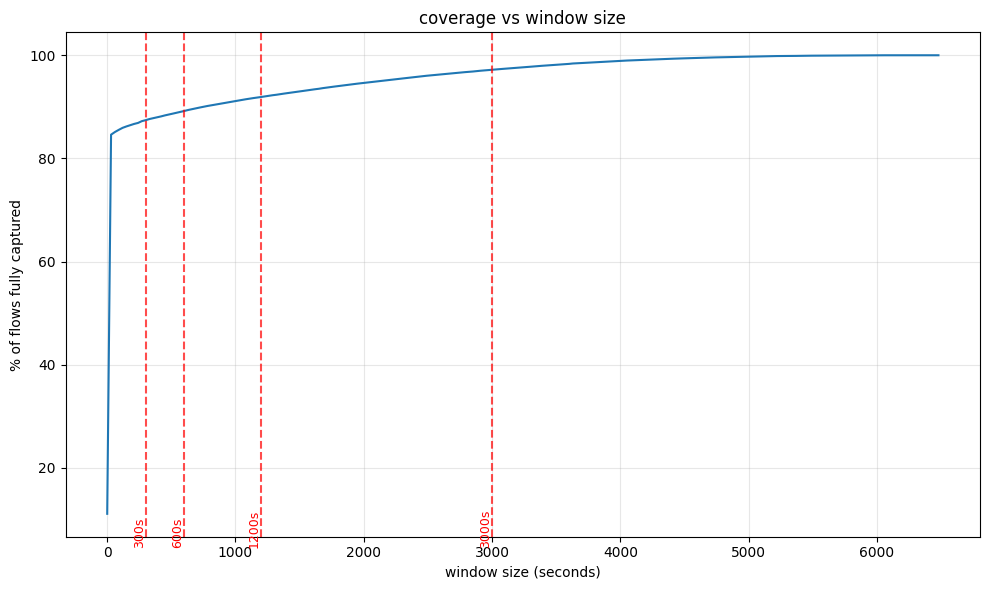

In [14]:
#compute coverage percentage for a range of window sizes
#see if there's any elbow to determine coverage for bucket
window_range = np.arange(0, 6500, 30)  #every 30 seconds, from 0 to max duration
coverage = [(df_clean["flow_duration"] <= w).mean() * 100 for w in window_range]

plt.figure(figsize=(10, 6))
plt.plot(window_range, coverage)
plt.xlabel("window size (seconds)")
plt.ylabel("% of flows fully captured")
plt.title("coverage vs window size")
plt.grid(True, alpha=0.3)

#mark candidate options for reference
plt.axvline(x=300, color="red", linestyle="--", alpha=0.7, label="candidate window (300s)")
plt.axvline(x=600, color="red", linestyle="--", alpha=0.7, label="candidate window (600s)")
plt.axvline(x=1200, color="red", linestyle="--", alpha=0.7, label="candidate window (1200s)")
plt.axvline(x=3000, color="red", linestyle="--", alpha=0.7, label="candidate window (3000s)")
plt.text(300, 5, "300s", rotation=90, fontsize=9, color="red", ha="right")
plt.text(600, 5, "600s", rotation=90, fontsize=9, color="red", ha="right")
plt.text(1200, 5, "1200s", rotation=90, fontsize=9, color="red", ha="right")
plt.text(3000, 5, "3000s", rotation=90, fontsize=9, color="red", ha="right")

plt.tight_layout()
#plt.savefig("coverage_vs_window.png", dpi=150, bbox_inches="tight")
plt.show()

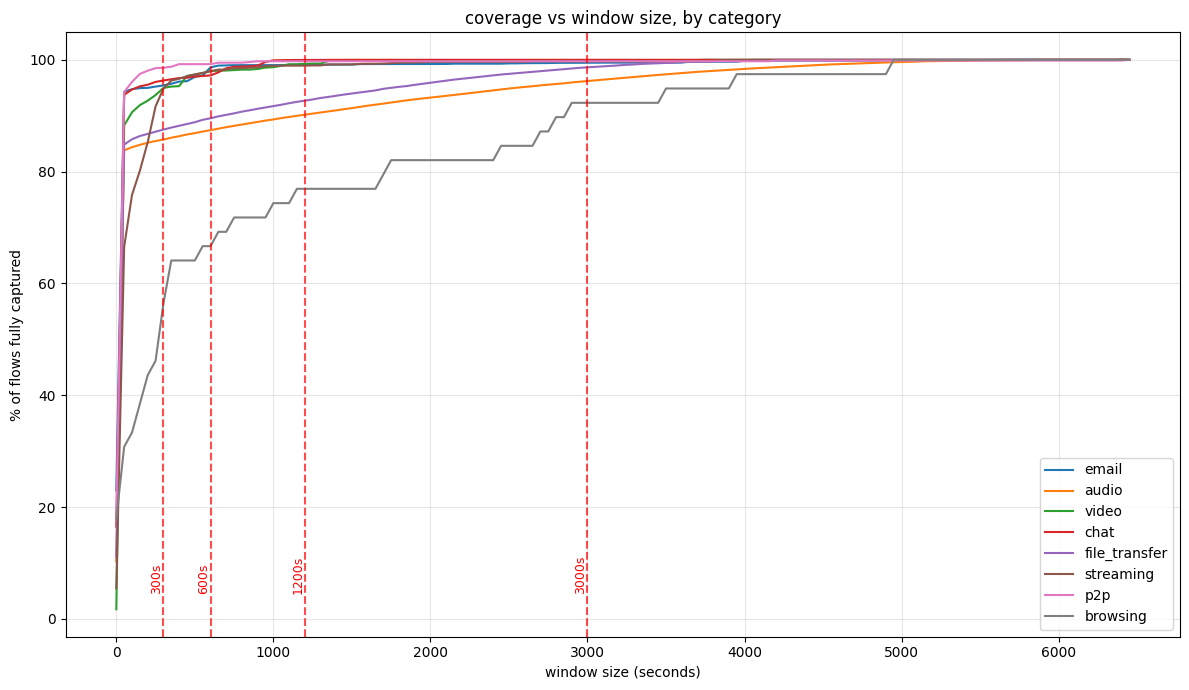

In [15]:
#coverage curve, but broken down by category
window_range = np.arange(0, 6500, 50)

plt.figure(figsize=(12, 7))
for cat in df_clean["category"].unique():
    cat_durations = df_clean[df_clean["category"] == cat]["flow_duration"]
    coverage = [(cat_durations <= w).mean() * 100 for w in window_range]
    plt.plot(window_range, coverage, label=cat)

plt.xlabel("window size (seconds)")
plt.ylabel("% of flows fully captured")
plt.title("coverage vs window size, by category")
plt.legend()
plt.grid(True, alpha=0.3)

#add the 1200s and 3000s reference line
plt.axvline(x=300, color="red", linestyle="--", alpha=0.7, label="candidate window (300s)")
plt.axvline(x=600, color="red", linestyle="--", alpha=0.7, label="candidate window (600s)")
plt.axvline(x=1200, color="red", linestyle="--", alpha=0.7, label="candidate window (1200s)")
plt.axvline(x=3000, color="red", linestyle="--", alpha=0.7, label="candidate window (3000s)")
plt.text(300, 5, "300s", rotation=90, fontsize=9, color="red", ha="right")
plt.text(600, 5, "600s", rotation=90, fontsize=9, color="red", ha="right")
plt.text(1200, 5, "1200s", rotation=90, fontsize=9, color="red", ha="right")
plt.text(3000, 5, "3000s", rotation=90, fontsize=9, color="red", ha="right")

plt.tight_layout()
#plt.savefig("coverage_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

#just choose 3000s as coverage for bucketing

# Bucketing

In [19]:
#ADJUST THE BUCKETS
#300s coverage: 30 * 10
BUCKET_SIZE_SECONDS = 30
NUM_BUCKETS = 10 

#bytes sent and received per bucket
def bucket_bytes_by_direction(packet_seq, bucket_size=BUCKET_SIZE_SECONDS, num_buckets=NUM_BUCKETS):
    if len(packet_seq) == 0:
        return np.zeros(num_buckets * 2)

    flow_start = packet_seq[0][0]
    bytes_out = np.zeros(num_buckets)
    bytes_in = np.zeros(num_buckets)

    for timestamp, size, direction in packet_seq:
        elapsed = timestamp - flow_start
        bucket_index = int(elapsed // bucket_size)
        if bucket_index < num_buckets:
            if direction > 0:
                bytes_out[bucket_index] += size
            else:
                bytes_in[bucket_index] += size

    return np.concatenate([bytes_out, bytes_in])

#packets sent and received per bucket
def bucket_packets_by_direction(packet_seq, bucket_size=BUCKET_SIZE_SECONDS, num_buckets=NUM_BUCKETS):
    if len(packet_seq) == 0:
        return np.zeros(num_buckets * 2)

    flow_start = packet_seq[0][0]
    packets_out = np.zeros(num_buckets)
    packets_in = np.zeros(num_buckets)

    for timestamp, size, direction in packet_seq:
        elapsed = timestamp - flow_start
        bucket_index = int(elapsed // bucket_size)
        if bucket_index < num_buckets:
            if direction > 0:
                packets_out[bucket_index] += 1
            else:
                packets_in[bucket_index] += 1

    return np.concatenate([packets_out, packets_in])

#mean and std of time between consecutive packets per bucket
def bucket_timing_stats(packet_seq, bucket_size=BUCKET_SIZE_SECONDS, num_buckets=NUM_BUCKETS):
    if len(packet_seq) < 2:
        return np.zeros(num_buckets * 2)  #mean and std per bucket

    flow_start = packet_seq[0][0]
    bucket_gaps = [[] for _ in range(num_buckets)]

    timestamps = [p[0] for p in packet_seq]
    for i in range(1, len(timestamps)):
        gap = timestamps[i] - timestamps[i-1]
        elapsed = timestamps[i] - flow_start
        bucket_index = int(elapsed // bucket_size)
        if bucket_index < num_buckets:
            bucket_gaps[bucket_index].append(gap)

    mean_gaps = np.array([np.mean(g) if g else 0 for g in bucket_gaps])
    std_gaps = np.array([np.std(g) if g else 0 for g in bucket_gaps])

    return np.concatenate([mean_gaps, std_gaps])

#mean and std of bytes of each packet per bucket
def bucket_size_stats(packet_seq, bucket_size=BUCKET_SIZE_SECONDS, num_buckets=NUM_BUCKETS):
    if len(packet_seq) == 0:
        return np.zeros(num_buckets * 2)  #mean and std per bucket

    flow_start = packet_seq[0][0]
    bucket_sizes = [[] for _ in range(num_buckets)]

    for timestamp, size, direction in packet_seq:
        elapsed = timestamp - flow_start
        bucket_index = int(elapsed // bucket_size)
        if bucket_index < num_buckets:
            bucket_sizes[bucket_index].append(size)

    mean_sizes = np.array([np.mean(s) if s else 0 for s in bucket_sizes])
    std_sizes = np.array([np.std(s) if s else 0 for s in bucket_sizes])

    return np.concatenate([mean_sizes, std_sizes])

In [20]:
#8 * 10 more columns here 

#apply and expand into columns: bytes_out_0...9, bytes_in_0...9
bytes_result = df_clean["packet_seq"].apply(bucket_bytes_by_direction)
bytes_cols = [f"bytes_out_{i}" for i in range(NUM_BUCKETS)] + [f"bytes_in_{i}" for i in range(NUM_BUCKETS)]
df_bytes = pd.DataFrame(bytes_result.tolist(), columns=bytes_cols, index=df_clean.index)

#apply and expand into columns: packets_out_0...9, packets_in_0...9
packets_result = df_clean["packet_seq"].apply(bucket_packets_by_direction)
packets_cols = [f"packets_out_{i}" for i in range(NUM_BUCKETS)] + [f"packets_in_{i}" for i in range(NUM_BUCKETS)]
df_packets = pd.DataFrame(packets_result.tolist(), columns=packets_cols, index=df_clean.index)

#timing stats: mean and std of inter-arrival time, per bucket
timing_result = df_clean["packet_seq"].apply(bucket_timing_stats)
timing_cols = [f"gap_mean_{i}" for i in range(NUM_BUCKETS)] + [f"gap_std_{i}" for i in range(NUM_BUCKETS)]
df_timing = pd.DataFrame(timing_result.tolist(), columns=timing_cols, index=df_clean.index)

#size stats: mean and std of packet size, per bucket
size_result = df_clean["packet_seq"].apply(bucket_size_stats)
size_cols = [f"size_mean_{i}" for i in range(NUM_BUCKETS)] + [f"size_std_{i}" for i in range(NUM_BUCKETS)]
df_size = pd.DataFrame(size_result.tolist(), columns=size_cols, index=df_clean.index)

In [21]:
print(f"before shape: {df_clean.shape}")

#combine with original columns
df_clean_features = pd.concat([df_clean, df_bytes, df_packets, df_timing, df_size], axis=1)
print(f"after shape: {df_clean_features.shape}")
df_clean_features.head(3)

before shape: (188670, 11)
after shape: (188670, 91)


,filepath,filename,stream_id,part,network_type,category,flow_key,packet_seq,flow_duration,packet_count,total_bytes,bytes_out_0,bytes_out_1,bytes_out_2,bytes_out_3,bytes_out_4,bytes_out_5,bytes_out_6,bytes_out_7,bytes_out_8,bytes_out_9,bytes_in_0,bytes_in_1,bytes_in_2,bytes_in_3,bytes_in_4,bytes_in_5,bytes_in_6,bytes_in_7,bytes_in_8,bytes_in_9,packets_out_0,packets_out_1,packets_out_2,packets_out_3,packets_out_4,packets_out_5,packets_out_6,packets_out_7,packets_out_8,packets_out_9,packets_in_0,packets_in_1,packets_in_2,packets_in_3,packets_in_4,packets_in_5,packets_in_6,packets_in_7,packets_in_8,packets_in_9,gap_mean_0,gap_mean_1,gap_mean_2,gap_mean_3,gap_mean_4,gap_mean_5,gap_mean_6,gap_mean_7,gap_mean_8,gap_mean_9,gap_std_0,gap_std_1,gap_std_2,gap_std_3,gap_std_4,gap_std_5,gap_std_6,gap_std_7,gap_std_8,gap_std_9,size_mean_0,size_mean_1,size_mean_2,size_mean_3,size_mean_4,size_mean_5,size_mean_6,size_mean_7,size_mean_8,size_mean_9,size_std_0,size_std_1,size_std_2,size_std_3,size_std_4,size_std_5,size_std_6,size_std_7,size_std_8,size_std_9
0,/kaggle/input/datasets/trayne/pcaps-data/NonVP...,email1a.pcap,email1,a,non_vpn,email,"(131.202.240.93, 57806, 255.255.255.255, 10505...","[(1432572763.37583, 127, 1)]",0.000000,1,127,127.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,127.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,/kaggle/input/datasets/trayne/pcaps-data/NonVP...,email1a.pcap,email1,a,non_vpn,email,"(131.202.240.183, 63970, 255.255.255.255, 1900...","[(1432572763.491782, 215, 1), (1432572763.4919...",556.737612,20,4300,430.0,0.0,430.0,0.0,430.0,0.0,430.0,0.0,430.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,2.0,0.0,2.0,0.0,2.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000202,0.0,30.801505,0.0,30.902566,0.0,31.153615,0.0,30.553177,0.0,0.0,0.0,30.801299,0.0,30.902367,0.0,31.153435,0.0,30.552981,0.0,215.0,0.0,215.0,0.0,215.0,0.0,215.0,0.0,215.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,/kaggle/input/datasets/trayne/pcaps-data/NonVP...,email1a.pcap,email1,a,non_vpn,email,"(131.202.240.117, 54995, 255.255.255.255, 1050...","[(1432572763.515294, 131, 1)]",0.000000,1,131,131.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,131.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# EDA

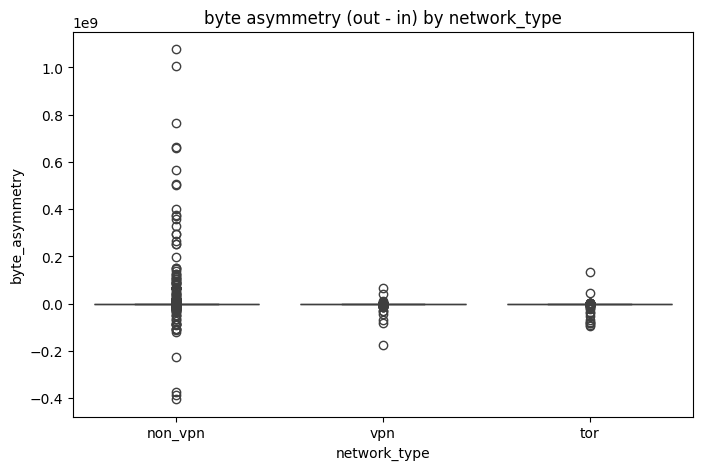

In [22]:
#asymmetry between bytes out and bytes in, across network_type
bytes_out_cols = [c for c in df_clean_features.columns if c.startswith("bytes_out_")]
bytes_in_cols = [c for c in df_clean_features.columns if c.startswith("bytes_in_")]

df_clean_features["total_bytes_out"] = df_clean_features[bytes_out_cols].sum(axis=1)
df_clean_features["total_bytes_in"] = df_clean_features[bytes_in_cols].sum(axis=1)
df_clean_features["byte_asymmetry"] = df_clean_features["total_bytes_out"] - df_clean_features["total_bytes_in"]

plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean_features, x="network_type", y="byte_asymmetry")
plt.title("byte asymmetry (out - in) by network_type")
plt.show()

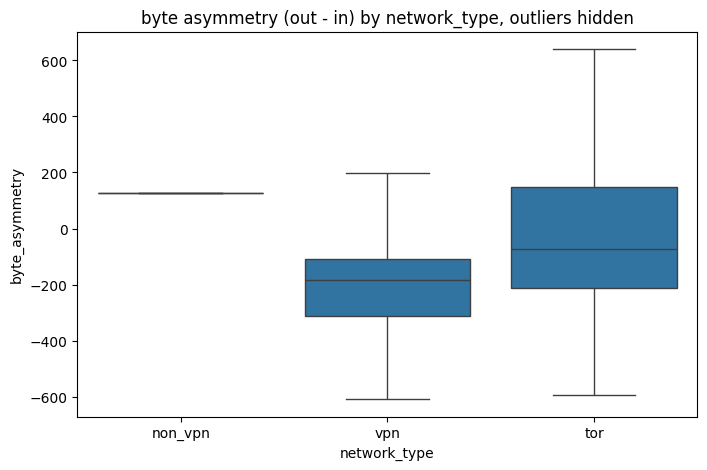

In [23]:
#boxplot with outliers hidden, so the box itself is visible
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean_features, x="network_type", y="byte_asymmetry", showfliers=False)
plt.title("byte asymmetry (out - in) by network_type, outliers hidden")
plt.show()

In [24]:
#precise stats, including iqr, for each network_type
df_clean_features.groupby("network_type")["byte_asymmetry"].describe()

#conclusion: splitting into bytes in and out does seem to help distinguish the network

,count,mean,std,min,25%,50%,75%,max
network_type,,,,,,,,
non_vpn,169585.0,58781.709054,6.212931e+06,-403674980.0,128.0,128.0,128.0,1.077733e+09
tor,1316.0,-509874.554711,7.204566e+06,-92339481.0,-213.0,-71.5,148.0,1.354516e+08
vpn,17769.0,-47964.985480,1.751368e+06,-173540373.0,-312.0,-182.0,-107.0,6.816142e+07


count    188670.000000
mean         93.210871
std           6.824039
min           0.000000
25%          95.000000
50%          95.000000
75%          95.000000
max          95.000000
Name: zero_bucket_pct, dtype: float64


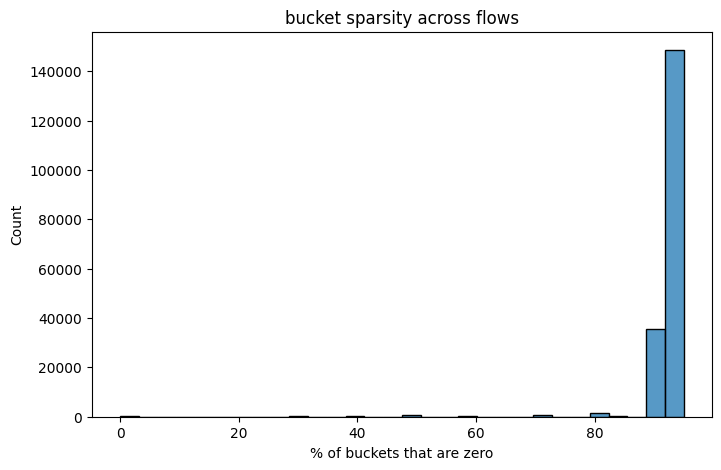

In [25]:
#sparsity check: % of buckets that are zero, per flow
feature_cols = bytes_out_cols + bytes_in_cols
zero_pct_per_flow = (df_clean_features[feature_cols] == 0).sum(axis=1) / len(feature_cols) * 100

df_clean_features["zero_bucket_pct"] = zero_pct_per_flow
print(df_clean_features["zero_bucket_pct"].describe())

plt.figure(figsize=(8, 5))
sns.histplot(df_clean_features["zero_bucket_pct"], bins=30)
plt.xlabel("% of buckets that are zero")
plt.title("bucket sparsity across flows")
plt.show()

In [26]:
#does sparsity differ meaningfully by network_type
df_clean_features.groupby("network_type")["zero_bucket_pct"].describe()

,count,mean,std,min,25%,50%,75%,max
network_type,,,,,,,,
non_vpn,169585.0,93.775540,5.991600,0.0,95.0,95.0,95.0,95.0
tor,1316.0,86.086626,18.251436,0.0,90.0,90.0,90.0,95.0
vpn,17769.0,88.349373,9.836109,0.0,90.0,90.0,90.0,95.0


,count,mean,std,min,25%,50%,75%,max
network_type,,,,,,,,
non_vpn,169585.0,0.331378,1.987228,0.0,0.041002,0.041179,0.042036,29.999901
tor,1316.0,0.641403,2.265261,0.0,0.000030,0.004018,0.043590,29.998437
vpn,17769.0,0.278668,1.547142,0.0,0.000072,0.000181,0.012994,29.851770


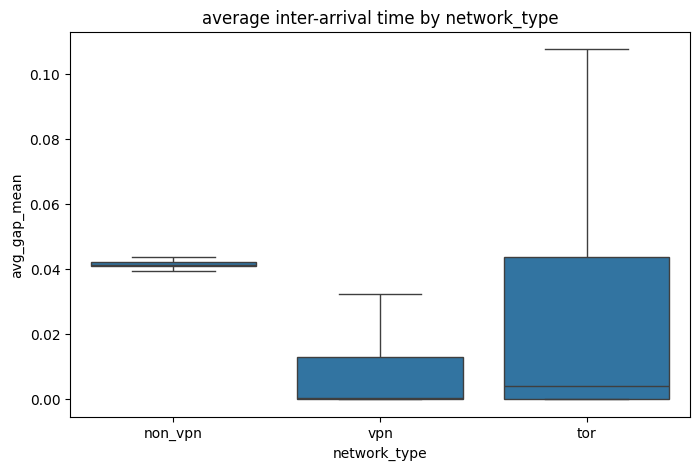

In [27]:
#summarise mean inter-arrival time (averaged across buckets) per network_type
gap_mean_cols = [c for c in df_clean_features.columns if c.startswith("gap_mean_")]
df_clean_features["avg_gap_mean"] = df_clean_features[gap_mean_cols].mean(axis=1)
display(df_clean_features.groupby("network_type")["avg_gap_mean"].describe())

#visualise it
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean_features, x="network_type", y="avg_gap_mean", showfliers=False)
plt.title("average inter-arrival time by network_type")
plt.show()

,count,mean,std,min,25%,50%,75%,max
network_type,,,,,,,,
non_vpn,169585.0,3.026783,46.489731,0.0,0.000000,0.0,0.00,8101.053976
tor,1316.0,37.739247,112.397090,0.0,0.150000,9.4,16.55,948.519813
vpn,17769.0,14.428333,25.665641,0.0,6.614126,9.4,16.80,628.371710


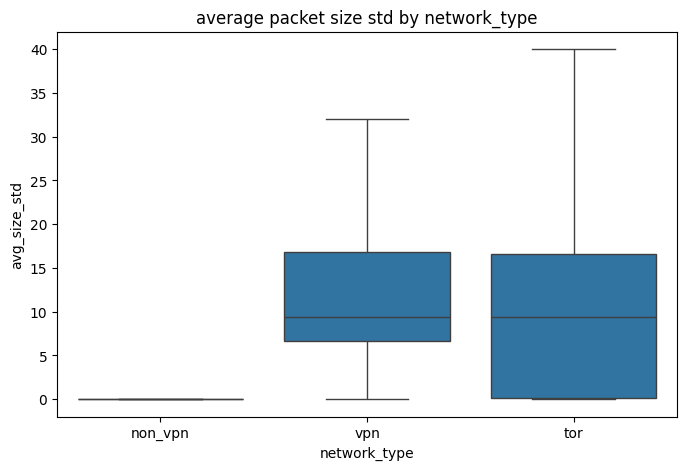

In [28]:
gap_std_cols = [c for c in df_clean_features.columns if c.startswith("size_std_")]
df_clean_features["avg_size_std"] = df_clean_features[gap_std_cols].mean(axis=1)
display(df_clean_features.groupby("network_type")["avg_size_std"].describe())

plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean_features, x="network_type", y="avg_size_std", showfliers=False)
plt.title("average packet size std by network_type")
plt.show()

# Splitting into train/validate/test set

In [29]:
print(df_clean_features.columns)

df_clean_features.head(1)

Index(['filepath', 'filename', 'stream_id', 'part', 'network_type', 'category',
       'flow_key', 'packet_seq', 'flow_duration', 'packet_count',
       'total_bytes', 'bytes_out_0', 'bytes_out_1', 'bytes_out_2',
       'bytes_out_3', 'bytes_out_4', 'bytes_out_5', 'bytes_out_6',
       'bytes_out_7', 'bytes_out_8', 'bytes_out_9', 'bytes_in_0', 'bytes_in_1',
       'bytes_in_2', 'bytes_in_3', 'bytes_in_4', 'bytes_in_5', 'bytes_in_6',
       'bytes_in_7', 'bytes_in_8', 'bytes_in_9', 'packets_out_0',
       'packets_out_1', 'packets_out_2', 'packets_out_3', 'packets_out_4',
       'packets_out_5', 'packets_out_6', 'packets_out_7', 'packets_out_8',
       'packets_out_9', 'packets_in_0', 'packets_in_1', 'packets_in_2',
       'packets_in_3', 'packets_in_4', 'packets_in_5', 'packets_in_6',
       'packets_in_7', 'packets_in_8', 'packets_in_9', 'gap_mean_0',
       'gap_mean_1', 'gap_mean_2', 'gap_mean_3', 'gap_mean_4', 'gap_mean_5',
       'gap_mean_6', 'gap_mean_7', 'gap_mean_8', 'gap_mean

,filepath,filename,stream_id,part,network_type,category,flow_key,packet_seq,flow_duration,packet_count,total_bytes,bytes_out_0,bytes_out_1,bytes_out_2,bytes_out_3,bytes_out_4,bytes_out_5,bytes_out_6,bytes_out_7,bytes_out_8,bytes_out_9,bytes_in_0,bytes_in_1,bytes_in_2,bytes_in_3,bytes_in_4,bytes_in_5,bytes_in_6,bytes_in_7,bytes_in_8,bytes_in_9,packets_out_0,packets_out_1,packets_out_2,packets_out_3,packets_out_4,packets_out_5,packets_out_6,packets_out_7,packets_out_8,packets_out_9,packets_in_0,packets_in_1,packets_in_2,packets_in_3,packets_in_4,packets_in_5,packets_in_6,packets_in_7,packets_in_8,packets_in_9,gap_mean_0,gap_mean_1,gap_mean_2,gap_mean_3,gap_mean_4,gap_mean_5,gap_mean_6,gap_mean_7,gap_mean_8,gap_mean_9,gap_std_0,gap_std_1,gap_std_2,gap_std_3,gap_std_4,gap_std_5,gap_std_6,gap_std_7,gap_std_8,gap_std_9,size_mean_0,size_mean_1,size_mean_2,size_mean_3,size_mean_4,size_mean_5,size_mean_6,size_mean_7,size_mean_8,size_mean_9,size_std_0,size_std_1,size_std_2,size_std_3,size_std_4,size_std_5,size_std_6,size_std_7,size_std_8,size_std_9,total_bytes_out,total_bytes_in,byte_asymmetry,zero_bucket_pct,avg_gap_mean,avg_size_std
0,/kaggle/input/datasets/trayne/pcaps-data/NonVP...,email1a.pcap,email1,a,non_vpn,email,"(131.202.240.93, 57806, 255.255.255.255, 10505...","[(1432572763.37583, 127, 1)]",0.0,1,127,127.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,127.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,127.0,0.0,127.0,95.0,0.0,0.0


In [31]:
#dropping category cause some network types are missing within some categories
#e.g. browsing only has Tor
X = df_clean_features.drop(columns=['filepath', 'filename', 'stream_id', 'part', 'category',
                                    'flow_key', 'packet_seq', 'flow_duration', 'packet_count',
                                    'total_bytes', 'network_type', 'total_bytes_out', 'total_bytes_in',
                                    'byte_asymmetry', 'zero_bucket_pct', 'avg_gap_mean',
                                    'avg_size_std'])

y = df_clean_features["network_type"]

print(X.shape)
print(X.columns)

(188670, 80)
Index(['bytes_out_0', 'bytes_out_1', 'bytes_out_2', 'bytes_out_3',
       'bytes_out_4', 'bytes_out_5', 'bytes_out_6', 'bytes_out_7',
       'bytes_out_8', 'bytes_out_9', 'bytes_in_0', 'bytes_in_1', 'bytes_in_2',
       'bytes_in_3', 'bytes_in_4', 'bytes_in_5', 'bytes_in_6', 'bytes_in_7',
       'bytes_in_8', 'bytes_in_9', 'packets_out_0', 'packets_out_1',
       'packets_out_2', 'packets_out_3', 'packets_out_4', 'packets_out_5',
       'packets_out_6', 'packets_out_7', 'packets_out_8', 'packets_out_9',
       'packets_in_0', 'packets_in_1', 'packets_in_2', 'packets_in_3',
       'packets_in_4', 'packets_in_5', 'packets_in_6', 'packets_in_7',
       'packets_in_8', 'packets_in_9', 'gap_mean_0', 'gap_mean_1',
       'gap_mean_2', 'gap_mean_3', 'gap_mean_4', 'gap_mean_5', 'gap_mean_6',
       'gap_mean_7', 'gap_mean_8', 'gap_mean_9', 'gap_std_0', 'gap_std_1',
       'gap_std_2', 'gap_std_3', 'gap_std_4', 'gap_std_5', 'gap_std_6',
       'gap_std_7', 'gap_std_8', 'gap_std_9',

In [36]:
from sklearn.model_selection import GroupShuffleSplit

#use stream_id for grouping the split
groups = df_clean_features["stream_id"]

#split 1: 70% train, 30% temp, grouped by stream_id
gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=4266)
train_idx, temp_idx = next(gss.split(X, y, groups=groups))

X_train, X_temp = X.iloc[train_idx], X.iloc[temp_idx]
y_train, y_temp = y.iloc[train_idx], y.iloc[temp_idx]
groups_temp = groups.iloc[temp_idx]

#split 2: temp into 50% validation, 50% test, grouped by stream_id
gss_temp = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=4266)
val_idx, test_idx = next(gss_temp.split(X_temp, y_temp, groups=groups_temp))

X_val, X_test = X_temp.iloc[val_idx], X_temp.iloc[test_idx]
y_val, y_test = y_temp.iloc[val_idx], y_temp.iloc[test_idx]

#for verification
groups_train = groups.iloc[train_idx]
groups_val = groups_temp.iloc[val_idx]
groups_test = groups_temp.iloc[test_idx]

In [37]:
print("Train rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))

print("Train groups:", groups_train.nunique())
print("Validation groups:", groups_val.nunique())
print("Test groups:", groups_test.nunique())

print("Train-Val overlap:",
      len(set(groups_train) & set(groups_val)))

print("Train-Test overlap:",
      len(set(groups_train) & set(groups_test)))

print("Val-Test overlap:",
      len(set(groups_val) & set(groups_test)))

Train rows: 98327
Validation rows: 37556
Test rows: 52787
Train groups: 112
Validation groups: 24
Test groups: 25
Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


In [ ]:
#the last 2 cells are "leftover code" from the previous version
#CHECKING DISTRIBUTION
all_values_clean = X_clean.flatten()
nonzero_values_clean = all_values_clean[all_values_clean > 0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(nonzero_values_clean, bins=100)
axes[0].set_title("raw bucket values (nonzero) - cleaned")

axes[1].hist(np.log1p(nonzero_values_clean), bins=100)
axes[1].set_title("log1p-transformed bucket values - cleaned")

plt.tight_layout()
#plt.savefig("distribution_check_clean.png", dpi=150, bbox_inches="tight")
plt.show()

raw_skew_clean = skew(nonzero_values_clean)
log_skew_clean = skew(np.log1p(nonzero_values_clean))

print(f"skewness (raw, cleaned): {raw_skew_clean:.2f}")
print(f"skewness (log1p, cleaned): {log_skew_clean:.2f}")

In [ ]:
from sklearn.preprocessing import StandardScaler

#from results, use ln(1+x) then standardize. too much skew


#CLEANED data
X_clean_log = np.log1p(X_clean)  
scaler_clean = StandardScaler()
X_clean_scaled = scaler_clean.fit_transform(X_clean_log)

# Baseline